# BÀI THỰC HÀNH: XÂY DỰNG MẠNG CNN NHẬN DIỆN CHỮ SỐ VIẾT TAY (MNIST)

Chào các bạn! Trong bài thực hành này, chúng ta sẽ tự tay xây dựng một mạng Nơ-ron Tích chập (CNN) để dạy máy tính đọc các chữ số viết tay từ 0 đến 9.

## Bước 1: Import các công cụ cần thiết
Chúng ta sẽ sử dụng thư viện TensorFlow (Keras) để xây dựng mạng, và matplotlib để vẽ hình ảnh lên màn hình.

In [9]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np
import random

print(f"Phiên bản TensorFlow đang sử dụng: {tf.__version__}")

Phiên bản TensorFlow đang sử dụng: 2.19.0


## Bước 2: Tải và Tiền xử lý dữ liệu (Data Preparation)

Mạng nơ-ron không thích các con số quá lớn. Các điểm ảnh (pixel) ban đầu có giá trị độ sáng từ 0 đến 255.

Chúng ta sẽ chuẩn hóa (chia cho 255) để đưa các giá trị này về khoảng `[0, 1]`.

Đồng thời, ta cần định hình lại (reshape) ma trận dữ liệu thành khối 3D `(28, 28, 1)` để phù hợp với "kính lúp" (bộ lọc) của mạng CNN.

In [10]:
# Tải bộ dữ liệu MNIST (60.000 ảnh huấn luyện, 10.000 ảnh kiểm tra)
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Chuẩn hóa giá trị pixel về [0, 1]
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Định hình lại thành Tensor 3D (chiều cao, chiều rộng, kênh màu)
# Vì là ảnh xám nên kênh màu (depth) = 1
x_train = x_train.reshape((60000, 28, 28, 1))
x_test = x_test.reshape((10000, 28, 28, 1))

print("Kích thước tập huấn luyện:", x_train.shape)
print("Kích thước tập kiểm tra:", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Kích thước tập huấn luyện: (60000, 28, 28, 1)
Kích thước tập kiểm tra: (10000, 28, 28, 1)


## Bước 3: Xây dựng Kiến trúc Mạng CNN (Model Design)

Kiến trúc của chúng ta sẽ gồm 2 phần chính:

- **Khối trích xuất đặc trưng:** Dùng 2 lớp `Conv2D` (để tìm góc cạnh, nét chữ) kết hợp với `MaxPooling2D` (để nén dữ liệu và giữ lại đặc trưng rõ nhất).
- **Khối phân loại:** Duỗi phẳng dữ liệu (`Flatten`) và đưa vào lớp mạng truyền thống (`Dense`) với hàm `Softmax` để tính xác suất cho 10 con số (0-9).

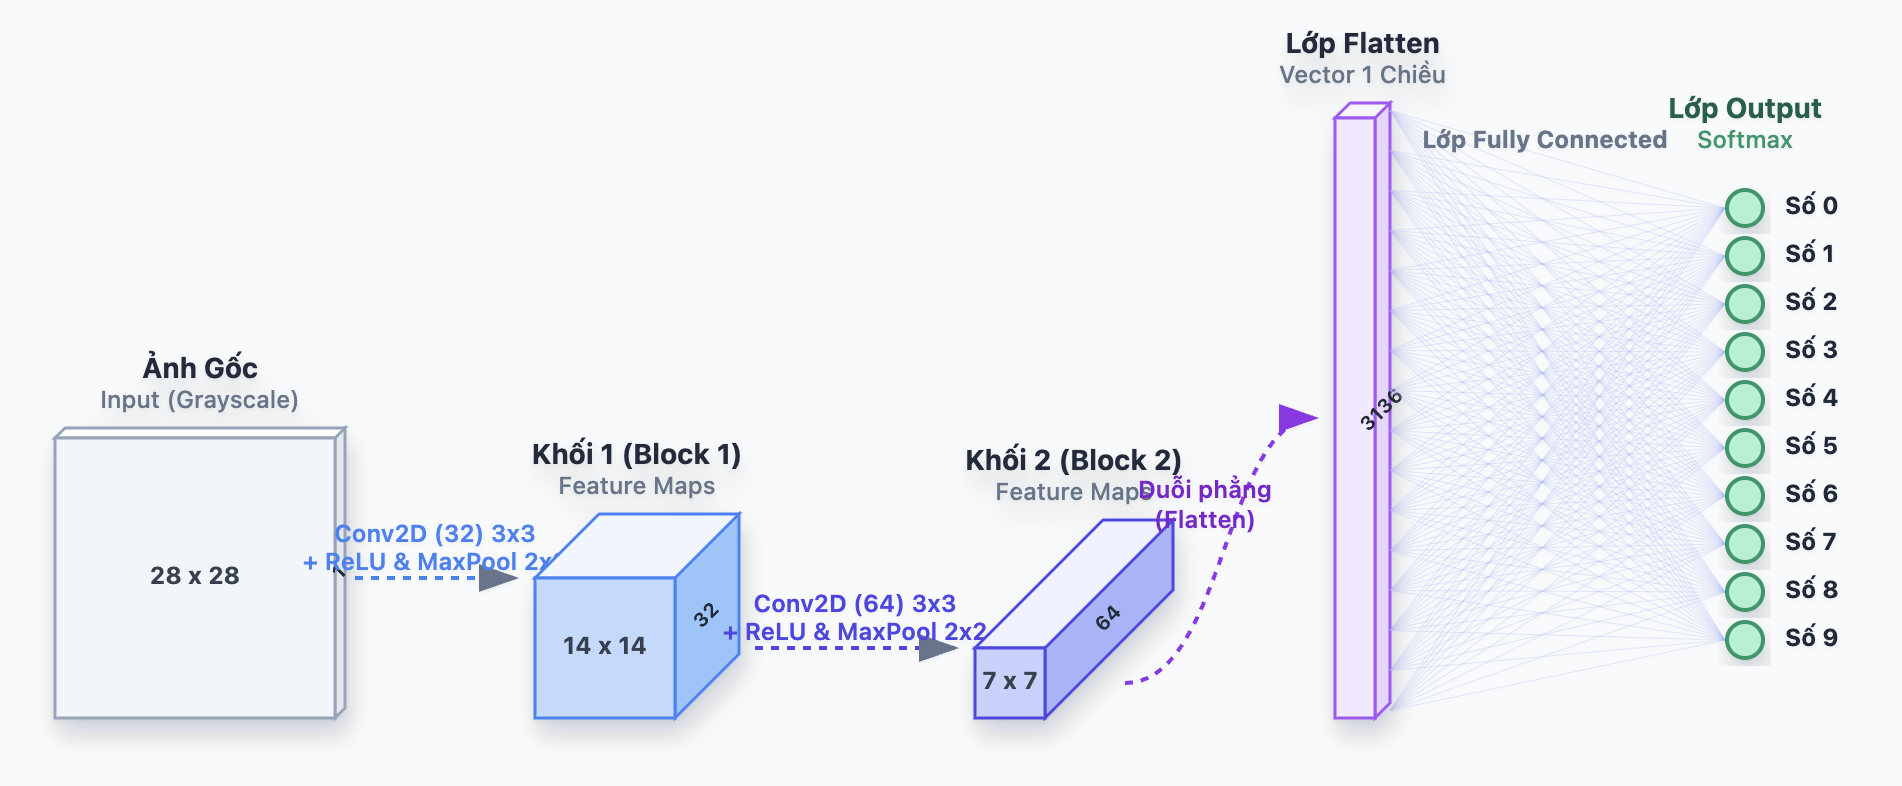

1. Sử dụng bộ lọc (Filter) kích thước $3\times3$

Tại sao: Các chữ số viết tay được cấu tạo từ những đặc trưng rất cơ bản như: nét thẳng, đường cong, góc nhọn, hoặc vòng lặp (như số 8 hay số 0). Kernel $3\times3$ là kích thước nhỏ nhất có thể bắt được các đặc điểm này một cách hiệu quả, đồng thời giữ cho số lượng tham số cực kỳ ít, giúp mô hình chạy nhanh và tránh bị "học vẹt" (overfitting).

2. Tăng dần số lượng bộ lọc (32 lên 64)

Tại sao: Đây là quy tắc thiết kế hình phễu chuẩn của CNN.
Ở Block 1 (32 bộ lọc), mạng sẽ tìm kiếm các đặc trưng cơ bản (như tìm xem chỗ nào có nét gạch ngang, chỗ nào có cạnh chéo).Sang Block 2 (64 bộ lọc), do kích thước ảnh đã bị thu nhỏ lại (chỉ còn 14x14), mạng cần nhiều không gian bộ nhớ (channels) hơn để kết hợp các đặc trưng cơ bản ở lớp trước thành các đặc trưng phức tạp hơn (ví dụ: nét thẳng + đường cong = hình dáng phần trên của số 9).

3. Khối gộp Max Pooling $2\times2$

Tại sao: Lớp này giúp giảm một nửa chiều dài và chiều rộng của Tensor (từ 28 xuống 14, rồi xuống 7). Việc này mang lại 2 lợi ích khổng lồ:
- Giảm khối lượng tính toán: Loại bỏ các thông tin không cần thiết.
- Tính bất biến với dịch chuyển (Translation Invariance): Bất kể người dùng viết số 7 hơi lệch sang trái hay sang phải, Max Pooling sẽ giúp mạng vẫn nhận diện được đó là số 7, vì nó chỉ giữ lại giá trị "nổi bật" nhất trong vùng $2\times2$.

4. Sử dụng hàm kích hoạt ReLU

Tại sao: Khác với các hàm cũ như Sigmoid hay Tanh, ReLU (đưa các giá trị âm về 0, giữ nguyên giá trị dương) giúp mạng huấn luyện cực kỳ nhanh và giải quyết được vấn đề "triệt tiêu đạo hàm" (vanishing gradient). Nó giúp các đặc trưng của chữ số nổi bật lên một cách rõ ràng.

5. Lớp Output 10 nơ-ron và Softmax

Tại sao: Bộ dữ liệu MNIST yêu cầu phân loại thành 10 kết quả (các số từ 0 đến 9), nên lớp cuối cùng bắt buộc phải có 10 nơ-ron. Hàm Softmax sẽ biến các con số thô (logits) thành một bảng phân bố xác suất có tổng bằng 1 (100%). Ví dụ: Mô hình sẽ tự tin xuất ra "98% là số 5, 1.5% là số 3, 0.5% là số 8".


In [11]:
model = models.Sequential()

# Block 1: 32 bộ lọc (size 3x3), hàm kích hoạt ReLU, thêm padding='same' để giữ nguyên 28x28 trước khi pool
model.add(layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(28, 28, 1)))

# Sau MaxPool: 14x14x32
model.add(layers.MaxPooling2D((2, 2)))

# Block 2: 64 bộ lọc (size 3x3), hàm kích hoạt ReLU, thêm padding='same' để giữ nguyên 14x14 trước khi pool
model.add(layers.Conv2D(64, (3, 3), activation='relu', padding='same'))

# Sau MaxPool: 7x7x64
model.add(layers.MaxPooling2D((2, 2)))

# Duỗi phẳng khối 3D thành Vector 1D (7 * 7 * 64 = 3136)
model.add(layers.Flatten())

# Khối phân loại: 10 nơ-ron output (tương ứng 10 chữ số)
model.add(layers.Dense(10, activation='softmax'))

# Hiển thị cấu trúc mạng
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        31,370 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,186 (196.04 KB)

 Trainable params: 50,186 (196.04 KB)

 Non-trainable params: 0 (0.00 B)

## Bước 4 & 5: Biên dịch và Huấn luyện mô hình (Compile & Train)

- **Hàm mất mát (Loss):** Đo lường mức độ dự đoán sai. Ta dùng `sparse_categorical_crossentropy` cho phân loại đa lớp.
- **Bộ tối ưu (Optimizer):** Dùng `adam` để tự động điều chỉnh trọng số giúp giảm Loss nhanh nhất.
- **Huấn luyện:** Cho máy học 5 chu kỳ (`epochs`) qua toàn bộ dữ liệu.

In [12]:
# Biên dịch mô hình
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Bắt đầu huấn luyện
print("Đang huấn luyện mô hình. Vui lòng đợi...")
history = model.fit(x_train, y_train, epochs=5, batch_size=64, validation_split=0.1)
print("Hoàn tất huấn luyện!")

Đang huấn luyện mô hình. Vui lòng đợi...
Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 74s 86ms/step - accuracy: 0.9373 - loss: 0.2080 - val_accuracy: 0.9830 - val_loss: 0.0627
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 70s 82ms/step - accuracy: 0.9810 - loss: 0.0618 - val_accuracy: 0.9863 - val_loss: 0.0528
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 84s 85ms/step - accuracy: 0.9862 - loss: 0.0444 - val_accuracy: 0.9847 - val_loss: 0.0607
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 80s 83ms/step - accuracy: 0.9888 - loss: 0.0359 - val_accuracy: 0.9885 - val_loss: 0.0372
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 83s 84ms/step - accuracy: 0.9912 - loss: 0.0284 - val_accuracy: 0.9895 - val_loss: 0.0416
Hoàn tất huấn luyện!


## Bước 6 & 7: Đánh giá và Dự đoán ngẫu nhiên

Sau khi học xong, ta mang tập dữ liệu kiểm tra (10.000 ảnh chưa từng thấy) ra để test. Đồng thời, bốc ngẫu nhiên 1 ảnh để xem mô hình đưa ra quyết định như thế nào.
verbose=0 - Không in chi tiết quá trình chạy ra màn hình.
Nếu để:
0: im lặng
1: hiện thanh tiến trình
2: hiện kết quả ngắn gọn theo từng bước

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.9891 - loss: 0.0319
Độ chính xác trên tập kiểm tra thực tế: 98.91%
------------------------------


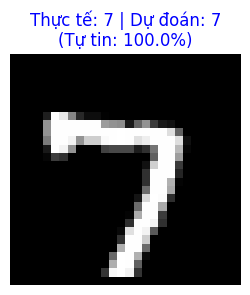

In [13]:
# Chấm điểm toàn bộ tập test
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=1)
print(f"Độ chính xác trên tập kiểm tra thực tế: {test_acc * 100:.2f}%")
print("-" * 30)

# Dự đoán 1 ảnh ngẫu nhiên
idx = random.randint(0, len(x_test) - 1)
sample_img = x_test[idx]
true_label = y_test[idx]

# Thêm 1 chiều batch để đưa vào mô hình (thành 1x28x28x1)
input_img = np.expand_dims(sample_img, axis=0)
predictions = model.predict(input_img, verbose=0)

predicted_label = np.argmax(predictions)
confidence = np.max(predictions) * 100

# Vẽ ảnh
plt.figure(figsize=(3, 3))
plt.imshow(sample_img.reshape(28, 28), cmap='gray')
color = 'blue' if predicted_label == true_label else 'red'
plt.title(f"Thực tế: {true_label} | Dự đoán: {predicted_label}\n(Tự tin: {confidence:.1f}%)", color=color)
plt.axis('off')
plt.show()

:## Bước 8: THỬ THÁCH THỰC TẾ - NHẬN DIỆN CHỮ VIẾT CỦA BẠN!

Bây giờ là lúc thú vị nhất!

Bạn hãy mở ứng dụng Paint trên máy tính.

- Dùng cọ (Brush) vẽ một con số bất kỳ (từ 0-9).
- Lưu ý: Hãy vẽ bằng mực **đen trên nền trắng**, vẽ nét đậm một chút và căn vào giữa khung hình.
- Lưu file dưới dạng `my_digit.png` hoặc `.jpg`.

Chạy ô code bên dưới. Một nút **Choose Files** sẽ hiện ra, hãy tải bức ảnh bạn vừa vẽ lên và xem phép màu!

> Ghi chú: Đoạn code này được tối ưu để chạy trên **Google Colab**.

Vui lòng bấm nút bên dưới để tải ảnh bạn vừa vẽ lên:


Saving 屏幕截图 2025-03-28 151025_0.png.webp to 屏幕截图 2025-03-28 151025_0.png.webp
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


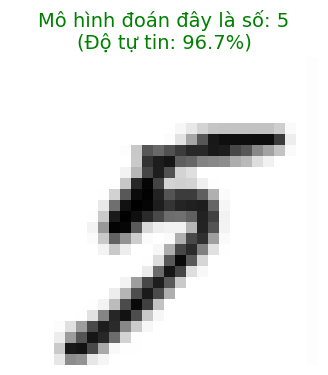


--- Chi tiết mức độ phân vân của mô hình ---
Khả năng là số 0: 0.00%
Khả năng là số 1: 0.00%
Khả năng là số 2: 1.39%
Khả năng là số 3: 1.11%
Khả năng là số 4: 0.00%
Khả năng là số 5: 96.75%
Khả năng là số 6: 0.75%
Khả năng là số 7: 0.00%
Khả năng là số 8: 0.01%
Khả năng là số 9: 0.00%


In [14]:
from google.colab import files
from PIL import Image, ImageOps
import io

print("Vui lòng bấm nút bên dưới để tải ảnh bạn vừa vẽ lên:")
uploaded = files.upload()

if uploaded:
    # Lấy tên file ảnh vừa tải lên
    filename = list(uploaded.keys())[0]

    # 1. Mở ảnh và chuyển sang hệ màu xám ('L')
    img = Image.open(io.BytesIO(uploaded[filename])).convert('L')

    # 2. Đảo màu (Cực kỳ quan trọng)
    # MNIST là ảnh chữ trắng nền đen. Bạn thường vẽ chữ đen nền trắng.
    # Nếu không đảo màu, mô hình sẽ không nhận dạng được!
    img = ImageOps.invert(img)

    # 3. Thu nhỏ về chuẩn 28x28 pixel
    img = img.resize((28, 28))

    # 4. Chuyển thành ma trận và chuẩn hóa về [0, 1]
    img_array = np.array(img) / 255.0

    # 5. Đưa vào mô hình dự đoán (reshape thành 1x28x28x1)
    my_input = img_array.reshape(1, 28, 28, 1)
    my_preds = model.predict(my_input)
    my_label = np.argmax(my_preds)
    my_conf = np.max(my_preds) * 100

    # Hiển thị kết quả
    plt.figure(figsize=(4, 4))
    plt.imshow(img_array, cmap='gray')
    plt.title(f"Mô hình đoán đây là số: {my_label}\n(Độ tự tin: {my_conf:.1f}%)",
              fontsize=14, color='green')
    plt.axis('off')
    plt.show()

    print("\n--- Chi tiết mức độ phân vân của mô hình ---")
    for i in range(10):
        print(f"Khả năng là số {i}: {my_preds[0][i]*100:.2f}%")
else:
    print("Bạn chưa tải ảnh lên!")

## Gợi ý khi chạy notebook
- Nếu chạy trên **Google Colab**, toàn bộ notebook sẽ hoạt động tốt, bao gồm cả phần tải ảnh bằng `files.upload()`.
- Nếu chạy trên **Jupyter Notebook cục bộ**, ô cuối dùng `google.colab` sẽ không hoạt động; khi đó cần đổi cách upload ảnh.

**Bước 9: BẢO QUẢN THÀNH QUẢ - LƯU MÔ HÌNH VÀO GOOGLE DRIVE**

Sau khi mô hình đã học xong và đạt điểm cao, chúng ta cần cất nó đi để ngày mai dùng tiếp.

Đầu tiên, chúng ta sẽ xin phép Google Colab được liên kết với Google Drive của bạn.

Sau đó, ta dùng lệnh model.save() để đóng gói toàn bộ mô hình (bao gồm cả cấu trúc mạng và các trọng số đã học) thành một tệp tin duy nhất có đuôi là .h5 (định dạng chuẩn của HDF5).

(Lưu ý: Khi chạy ô code này, Google sẽ hiện lên một bảng yêu cầu quyền truy cập vào Drive, bạn cứ bấm Cho phép / Allow nhé).

In [9]:
from google.colab import drive
import os

# 1. Kết nối với Google Drive của bạn
print("Đang kết nối với Google Drive...")
drive.mount('/content/drive')

# 2. Tạo một thư mục tên là 'Hoc_Sau' trên Drive để cho gọn gàng (nếu chưa có)
save_dir = '/content/drive/MyDrive/Hoc_Sau'
if not os.path.exists(save_dir):
    os.makedirs(save_dir)

# 3. Lưu mô hình
model_path = os.path.join(save_dir, 'my_mnist_cnn_model.h5')
model.save(model_path)

print(f"🎉 Chúc mừng! Mô hình đã được lưu an toàn tại: {model_path}")
print("Bây giờ bạn có thể tắt máy đi ngủ. Ngày mai mở lên không cần train lại nữa!")

Đang kết nối với Google Drive...
Mounted at /content/drive


🎉 Chúc mừng! Mô hình đã được lưu an toàn tại: /content/drive/MyDrive/Hoc_Sau/my_mnist_cnn_model.h5
Bây giờ bạn có thể tắt máy đi ngủ. Ngày mai mở lên không cần train lại nữa!


**Bước 10: TẢI LẠI MÔ HÌNH ĐÃ LƯU**

Giả sử hôm nay là một ngày mới, bạn vừa mở lại Google Colab. Bạn không cần chạy lại các bước xây dựng và huấn luyện mô hình ở trên nữa.
Bạn chỉ cần import các thư viện cần thiết, kết nối Drive, và dùng lệnh load_model() để "gọi" mô hình của bạn thức dậy làm việc ngay lập tức.

In [2]:
from tensorflow.keras.models import load_model
from google.colab import drive

# 1. Kết nối lại với Drive (nếu hôm nay bạn vừa mở lại máy)
drive.mount('/content/drive')

# 2. Đường dẫn tới file mô hình hôm qua bạn đã cất
model_path = '/content/drive/MyDrive/Hoc_Sau/my_mnist_cnn_model.h5'

# 3. Tải mô hình lên
print("Đang đánh thức mô hình...")
loaded_model = load_model(model_path)

print("Đã tải xong! Cấu trúc của mô hình vẫn nguyên vẹn như sau:")
loaded_model.summary()

# Bây giờ bạn có thể dùng 'loaded_model' để dự đoán ngay (giống như Bước 8)
# Ví dụ: loaded_model.predict(my_input)

Mounted at /content/drive
Đang đánh thức mô hình...


Đã tải xong! Cấu trúc của mô hình vẫn nguyên vẹn như sau:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        31,370 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,188 (196.05 KB)

 Trainable params: 50,186 (196.04 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

Dùng mô hình đã lưu để test:

Vui lòng bấm nút bên dưới để tải ảnh bạn vừa vẽ lên:


Saving Hard-to-recognize-images-in-the-MNIST-test-dataset_Q320.webp to Hard-to-recognize-images-in-the-MNIST-test-dataset_Q320.webp
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


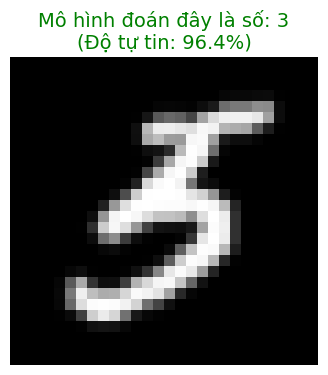


--- Chi tiết mức độ phân vân của mô hình ---
Khả năng là số 0: 0.00%
Khả năng là số 1: 0.00%
Khả năng là số 2: 0.00%
Khả năng là số 3: 96.37%
Khả năng là số 4: 0.00%
Khả năng là số 5: 3.63%
Khả năng là số 6: 0.00%
Khả năng là số 7: 0.00%
Khả năng là số 8: 0.00%
Khả năng là số 9: 0.00%


In [8]:
from google.colab import files
from PIL import Image, ImageOps
import io
import numpy as np # Thêm dòng này để import thư viện numpy
import matplotlib.pyplot as plt

print("Vui lòng bấm nút bên dưới để tải ảnh bạn vừa vẽ lên:")
uploaded = files.upload()

if uploaded:
    # Lấy tên file ảnh vừa tải lên
    filename = list(uploaded.keys())[0]

    # 1. Mở ảnh và chuyển sang hệ màu xám ('L')
    img = Image.open(io.BytesIO(uploaded[filename])).convert('L')

    # 2. Đảo màu (Cực kỳ quan trọng)
    # MNIST là ảnh chữ trắng nền đen. Bạn thường vẽ chữ đen nền trắng.
    # Nếu không đảo màu, mô hình sẽ không nhận dạng được!
    img = ImageOps.invert(img)

    # 3. Thu nhỏ về chuẩn 28x28 pixel
    img = img.resize((28, 28))

    # 4. Chuyển thành ma trận và chuẩn hóa về [0, 1]
    img_array = np.array(img) / 255.0

    # 5. Đưa vào mô hình dự đoán (reshape thành 1x28x28x1)
    my_input = img_array.reshape(1, 28, 28, 1)
    my_preds = loaded_model.predict(my_input)
    my_label = np.argmax(my_preds)
    my_conf = np.max(my_preds) * 100

    # Hiển thị kết quả
    plt.figure(figsize=(4, 4))
    plt.imshow(img_array, cmap='gray')
    plt.title(f"Mô hình đoán đây là số: {my_label}\n(Độ tự tin: {my_conf:.1f}%)",
              fontsize=14, color='green')
    plt.axis('off')
    plt.show()

    print("\n--- Chi tiết mức độ phân vân của mô hình ---")
    for i in range(10):
        print(f"Khả năng là số {i}: {my_preds[0][i]*100:.2f}%")
else:
    print("Bạn chưa tải ảnh lên!")